# WattShift: understand the data
Real SMARD observations, not sample prices. Historical hourly data remains hourly; recent quarter-hour data retains 15-minute bounds.

MW is power; MWh is energy. Energy (kWh) = power (kW) × duration (hours). Cost (€) = kWh × €/MWh ÷ 1000. Carbon (kgCO₂e) = kWh × gCO₂e/kWh ÷ 1000. Day-ahead prices are known only after publication. A price trough is not technically the net-load duck curve.

In [1]:
from pathlib import Path
import pandas as pd
root=Path.cwd()
if root.name=='notebooks': root=root.parent
pd.read_csv(root/'data/historical/prices.csv').head()

Out[0]: 
                   start_utc  ...  carbon_g_kwh
0  2024-01-01 00:00:00+00:00  ...           NaN
1  2024-01-01 01:00:00+00:00  ...           NaN
2  2024-01-01 02:00:00+00:00  ...           NaN
3  2024-01-01 03:00:00+00:00  ...           NaN
4  2024-01-01 04:00:00+00:00  ...           NaN

[5 rows x 4 columns]


## Carbon boundary
Generation is MWh per source interval. Compute a generation-weighted lifecycle estimate using config/emissions.json. Imports and pumped storage are excluded; other fuels use explicit approximations. This is not marginal avoided emissions. Missing categories stay unknown; nuclear is structurally zero after German shutdown. Carbon coverage is intentionally incomplete.

{'source': 'SMARD / Bundesnetzagentur', 'source_url': 'https://www.smard.de', 'adapter_url': 'https://www.smard.de/app/chart_data', 'license_url': 'https://www.smard.de/home/downloadcenter/download-marktdaten/', 'retrieved_at': '2026-10-16T22:34:28.374763+00:00', 'requested_start': '2024-06-01', 'requested_end': '2024-06-08', 'actual_start': '2024-06-01T00:00:00+00:00', 'actual_end': '2024-06-08T00:00:00+00:00', 'resolution': 'hour', 'price_unit': 'EUR/MWh', 'generation_unit': 'MWh per source interval', 'rows': 168, 'carbon_rows': 168, 'publication_times': 'not supplied by this endpoint; retrospective retrieval must not be treated as archived issue-time truth', 'carbon_method': 'config/emissions.json; retrospective domestic lifecycle proxy; not a live carbon forecast', 'sha256': '813365ed543555741b4f2f7ea7daec2c49cbbb1e2138436662844f05d02a98a6'}


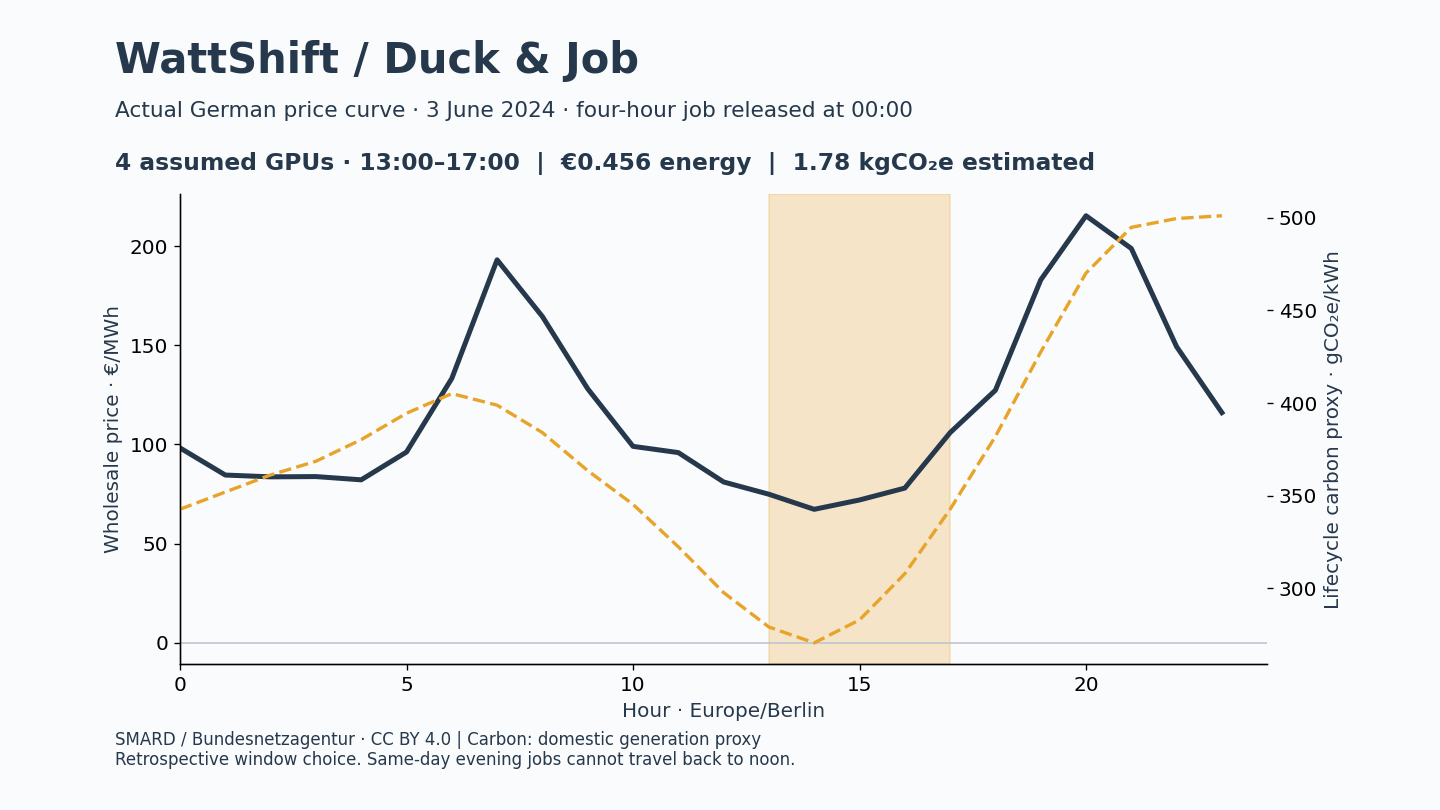

In [2]:
import json
print(json.loads((root/'data/summer/provenance.json').read_text()))
from IPython.display import Image,display
display(Image(filename=str(root/'docs/assets/price-carbon.png')))

## Forecast versus hindsight
Training ends before the held-out week. Lagged features use only previous observations. Revised historical data does not establish publication-time vintages. The calculator has perfect hindsight; the headline simulator uses a price forecast and lag-week carbon proxy. Negative energy prices do not imply negative retail or cloud bills.

In [3]:
report=json.loads((root/'apps/console/public/data/console.json').read_text())
pd.DataFrame(report['simulation']['totals']).T

Out[0]: 
           jobs  unavailable_jobs  ...   carbon_kg  carbon_saving_kg
immediate  48.0               0.0  ...  116.549919          0.000000
cheapest   48.0               0.0  ...  116.327292          0.222627
greenest   48.0               0.0  ...  116.874554         -0.324635
oracle     48.0               0.0  ...  115.230242          1.319677

[4 rows x 8 columns]
